<h1 style="background: linear-gradient(to right, #395761, #7799B6);
           color: white;
           padding: 22px;
           border-left: 10px solid #CEEB13;
           text-align: center;
           font-family: 'Roboto Mono', Menlo, 'Courier New', monospace;
           font-weight: 600;">
  Evaluating Reasoning: A Math Verifier
</h1>


A model that *sounds* right and a model that *is* right look identical until you check. This notebook is about the checker: a verifier that reads a free-form answer to a math problem, finds the final result inside it, and decides whether it matches the reference. Then it runs that verifier over a benchmark and reports a number.

That number is the backbone of everything that follows in this track. Every inference-time trick and every training run is judged by it, and during reinforcement learning the same verifier becomes the reward signal.

By the end of this notebook you will:

1. Know the four common ways to evaluate a language model and why this track uses verifiers,
2. Understand the four stages of a math verifier, and use the one in `reasoning_utils` on real model output,
3. Run the base model over a slice of MATH-500, read its failures, and see that swapping in the post-trained checkpoint is a one-line change,
4. See how sensitive a base model is to prompt wording, and why that matters for fair comparisons.

The string handling that makes a verifier robust (regular expressions, LaTeX cleanup, symbolic parsing) lives in [`reasoning_utils/verify.py`](reasoning_utils/verify.py) with comments. It is useful plumbing, not the point of this notebook, so here we show what each stage does by example and keep the focus on evaluation itself.

## `Step 1`: Four ways to evaluate, and why verifiers

| Method | How it works | Quantitative? | Needs |
|---|---|---|---|
| Multiple choice | the model picks A, B, C, or D; compare to the key | yes | a dataset with options |
| **Verifier** | the model answers freely; a program checks the answer | yes | a domain with checkable answers |
| Leaderboard | people compare two responses and vote | partly | a crowd |
| LLM judge | a stronger model grades the response against a rubric | partly | a stronger model and trust in it |

<div align="center"><img src="assets/evaluation-methods.svg" alt="Four panels: multiple choice compares a picked letter to a key, a verifier runs a program on a free-form answer, a leaderboard has people vote between two model answers, an LLM judge scores a response out of ten" width="900"/></div>

All four are in daily use, and each answers a different question. Multiple choice is cheap but tells you little about free-form reasoning. Leaderboards and LLM judges capture quality that has no single right answer, at the cost of being slow, subjective, or dependent on another model.

For the rest of this track we use **verifiers only**. Math problems reward step-by-step work, yet their final answers can be checked by a program, deterministically, in milliseconds. That property is what makes reinforcement learning with verifiable rewards possible: the check that scores a benchmark today is the reward that trains the model later. Code is the other big verifiable domain (run the tests), but executing untrusted code safely is its own project, so we stay with math.

## `Step 2`: Generate a solution

We start with the base model and a problem whose answer is a fraction, so that formatting differences will matter. The model is the pretrained [Qwen3-0.6B-Base](https://huggingface.co/Qwen/Qwen3-0.6B-Base); the text generation notebook explains everything behind `generate_text`.

In [1]:
from IPython.display import Latex, display

from reasoning_utils import (
    MATH_PROMPT,
    evaluate_math,
    extract_final_answer,
    generate_text,
    get_device,
    grade,
    is_equivalent,
    load_math500,
    load_qwen3,
    normalize_answer,
)
from reasoning_utils.plots import plot_benchmark_composition, plot_template_comparison

device = get_device()
model, tokenizer = load_qwen3("base", device=device)

device: cuda (NVIDIA L40S)


In [2]:
problem = r"What is the sum of the roots of $2x^2 - 7x + 3 = 0$?"

response = generate_text(model, tokenizer, problem, device, max_new_tokens=400, stream=True)

 To find the sum of the roots of the quadratic equation \(2x^2 - 7x + 3 = 0\), we can use the properties of quadratic equations. For a general quadratic equation of the form \(ax^2 + bx + c = 0\), the sum of the roots is given by \(-\frac{b}{a}\).

In the given equation \(2x^2 - 7x + 3 = 0\), the coefficients are \(a = 2\), \(b = -7\), and \(c = 3\). The sum of the roots is \(-\frac{-7}{2} = \frac{7}{2}\).

Let's confirm this by solving the quadratic equation using Python and then summing the roots.
```python
import sympy as sp

# Define the variable and the equation
x = sp.symbols('x')
equation = 2*x**2 - 7*x + 3

# Solve the equation to find the roots
roots = sp.solve(equation, x)

# Calculate the sum of the roots
sum_of_roots = sum(roots)
print(sum_of_roots)
```
```output
7/2
```
The sum of the roots of the quadratic equation \(2x^2 - 7x + 3 = 0\) is \(\boxed{\frac{7}{2}}\).

The raw output is LaTeX, because that is how math is written on the internet the model learned from. Jupyter can render it with [`IPython.display.Latex`](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html#IPython.display.Latex), which makes the structure of the answer easier to see.

In [3]:
display(Latex(response))

<IPython.core.display.Latex object>

Somewhere in that text is a final answer. The verifier's job is to find it, without a human in the loop, for thousands of responses that will each be formatted a little differently.

## `Step 3`: The verifier, stage by stage

<div align="center"><img src="assets/verifier-pipeline.svg" alt="A benchmark record feeds a problem to the LLM, whose free-form response flows through extract, normalize, and parse stages to the value 7/2, which is compared with the reference answer processed the same way" width="900"/></div>

<div align="center"><img src="assets/verifier.gif" alt="Animation stepping through the five verifier stages, showing the answer string after each one" width="900"/></div>

Four functions, one per stage, each a few lines of plain Python in `reasoning_utils/verify.py`:

| Stage | Function | What it does |
|---|---|---|
| extract | `extract_final_answer(text)` | returns the content of the last `\boxed{...}`; if there is none, the last number in the text; if there is none, the text itself |
| normalize | `normalize_answer(text)` | rewrites LaTeX and typography into one plain spelling: `\frac{a}{b}` to `(a)/(b)`, `\sqrt{x}` to `sqrt(x)`, `^` to `**`, strips `$`, `\left`, degree signs, thousands separators, lower-cases |
| compare | `is_equivalent(a, b)` | parses both sides with SymPy and checks that their difference simplifies to zero |
| grade | `grade(prediction, truth)` | normalizes both sides, splits tuples like `(a, b)` into parts, and requires every part to be equivalent |

### Extract

Math models overwhelmingly mark their final answer with `\boxed{...}`, a LaTeX convention that benchmark solutions use and that models imitate. Braces nest, so the function walks the string counting depth rather than using a regular expression. The fallbacks matter: a wrong extraction is graded wrong, which you can see in the logs, while a missing extraction can hide a bug.

In [4]:
print("from the model's response:", repr(extract_final_answer(response)))
for sample in [r"so \boxed{\dfrac{7}{2}} is the sum", r"\boxed{ 3.5 }", "the roots add up to 7/2 as expected", "no idea"]:
    print(f"{sample!r:45} -> {extract_final_answer(sample)!r}")

from the model's response: '\\frac{7}{2}'
'so \\boxed{\\dfrac{7}{2}} is the sum'        -> '\\dfrac{7}{2}'
'\\boxed{ 3.5 }'                              -> '3.5'
'the roots add up to 7/2 as expected'         -> '7/2'
'no idea'                                     -> 'no idea'


### Normalize

The same value has many spellings. Normalization maps all of them to one plain form that a symbolic engine can read. It is a list of rewrite rules, and every rule in the file exists because some real model output needed it.

In [5]:
for sample in [r"\frac{7}{2}", r"\dfrac{7}{2}", r"$\frac{7}{2}$", r"\left(\frac{7}{2}\right)", r"\text{7/2}", "3.5", r"45^\circ", "2,500", "3²"]:
    print(f"{sample!r:28} -> {normalize_answer(sample)!r}")

'\\frac{7}{2}'               -> '(7)/(2)'
'\\dfrac{7}{2}'              -> '(7)/(2)'
'$\\frac{7}{2}$'             -> '(7)/(2)'
'\\left(\\frac{7}{2}\\right)' -> '((7)/(2))'
'\\text{7/2}'                -> '7/2'
'3.5'                        -> '3.5'
'45^\\circ'                  -> '45'
'2,500'                      -> '2500'
'3²'                         -> '3**2'


### Compare

After normalization, `\frac{7}{2}` and `\dfrac{7}{2}` are the same string. But `(7)/(2)`, `7/2`, `3.5`, and `14/4` are not, and they are all the same number. String equality is not enough, so both sides go to [SymPy](https://www.sympy.org/), a symbolic mathematics library, through its [expression parser](https://docs.sympy.org/latest/modules/parsing.html). If the difference simplifies to zero, the answers agree. That one call handles fractions, decimals, roots, and even algebraic expressions. Anything SymPy cannot parse, including runaway generations longer than 2000 characters, counts as not equal.

In [6]:
pairs = [("(7)/(2)", "7/2"), ("3.5", "7/2"), ("14/4", "7/2"), ("sqrt(8)", "2*sqrt(2)"), ("x**2 + 2x + 1", "(x+1)**2"), ("7/2", "7/3"), ("(7/2, 1)", "(14/4, 1)")]
for a, b in pairs:
    print(f"{a!r:18} vs {b!r:14} -> {is_equivalent(normalize_answer(a), normalize_answer(b))}")

'(7)/(2)'          vs '7/2'          -> True
'3.5'              vs '7/2'          -> True
'14/4'             vs '7/2'          -> True
'sqrt(8)'          vs '2*sqrt(2)'    -> True
'x**2 + 2x + 1'    vs '(x+1)**2'     -> True
'7/2'              vs '7/3'          -> False
'(7/2, 1)'         vs '(14/4, 1)'    -> False


Everything agrees except the last pair. `(7/2, 1)` and `(14/4, 1)` are the same point, but SymPy parses each as a tuple and does not simplify `tuple - tuple`. Coordinate pairs, intervals, and lists of roots are common in benchmarks, which is what the final stage is for.

### Grade

`grade` is the function the rest of the track calls. It normalizes both sides, splits bracketed comma-separated answers into parts, and requires every part to be equivalent in order: `(2, 5)` is not `(5, 2)`, and a different number of parts is a mismatch.

A verifier silently decides which training signals your model receives, so it deserves a test table more than almost anything else in this track. This table also lives in `tests/test_verify.py` and runs with `uv run pytest`.

In [7]:
# (prediction, reference, expected verdict)
cases = [
    ("5/8", r"\frac{5}{8}", True),
    ("(5)/(8)", "5/8", True),
    (r"\frac{\sqrt{18}}{3}", "sqrt(2)", True),
    (r"\( \frac{1}{3} + \frac{1}{6} \)", "1/2", True),
    ("(2, 5)", "(2,5)", True),
    ("(5, 2)", "(2, 5)", False),
    ("(1, 2, 3)", "(1, 2)", False),
    ("0.25", "1/4", True),
    ("0.6666666667", "2/3", False),
    ("2,500/5", "500", True),
    (r"\text{3/7}", "3/7", True),
    ("40%", "2/5", False),
    (r"3\cdot 5/6", "5/2", True),
    (r"45^\circ", "45", True),
    (r"\left(\frac{5}{8}\right)", "5/8", True),
    ("3²", "9", True),
    ("[2, 5]", "(2, 5)", True),
    ("2.5e-2", "0.025", True),
    ("(-4)^2", "16", True),
    ("\u22127", "-7", True),
    ("(7/2, 1)", "(14/4, 1)", True),
]

print(f"{'prediction':<36}{'reference':<16}{'expect':<8}{'got':<8}status")
n_pass = 0
for pred, truth, expected in cases:
    got = grade(pred, truth)
    ok = got == expected
    n_pass += ok
    print(f"{pred!r:<36}{truth!r:<16}{str(expected):<8}{str(got):<8}{'PASS' if ok else 'FAIL'}")
print(f"\n{n_pass}/{len(cases)} passed")

prediction                          reference       expect  got     status
'5/8'                               '\\frac{5}{8}'  True    True    PASS
'(5)/(8)'                           '5/8'           True    True    PASS
'\\frac{\\sqrt{18}}{3}'             'sqrt(2)'       True    True    PASS
'\\( \\frac{1}{3} + \\frac{1}{6} \\)''1/2'           True    True    PASS
'(2, 5)'                            '(2,5)'         True    True    PASS
'(5, 2)'                            '(2, 5)'        False   False   PASS
'(1, 2, 3)'                         '(1, 2)'        False   False   PASS
'0.25'                              '1/4'           True    True    PASS
'0.6666666667'                      '2/3'           False   False   PASS
'2,500/5'                           '500'           True    True    PASS
'\\text{3/7}'                       '3/7'           True    True    PASS
'40%'                               '2/5'           False   False   PASS
'3\\cdot 5/6'                       '5/2'       

> **Try it.** Two of these verdicts are design decisions rather than mathematical facts: `0.6666666667` is graded as not equal to `2/3`, and `40%` is graded as not equal to `2/5`. Argue the other side of each. Then write a case you think should pass and does not (an interval like `[0, 3)`, or an answer with units like `12 \text{ cm}`), and add a rule to `normalize_answer` so it does.

Finally, the whole pipeline on the response from Step 2:

In [8]:
predicted = extract_final_answer(response)
print(f"extracted:  {predicted!r}")
print(f"normalized: {normalize_answer(predicted)!r}")
print(f"correct:    {grade(predicted, r'\frac{7}{2}')}")

extracted:  '\\frac{7}{2}'
normalized: '(7)/(2)'
correct:    True


## `Step 4`: The benchmark

[MATH-500](https://huggingface.co/datasets/HuggingFaceH4/MATH-500) is a set of 500 competition-style problems drawn from the larger [MATH dataset](https://arxiv.org/abs/2103.03874), spread across seven subjects and five difficulty levels. Three things make it a good fit here: it is big enough to be meaningful and small enough to run many times, later notebooks train on a disjoint part of MATH so it stays a clean held-out set, and it is widely reported, so your numbers are comparable to published ones.

Each record has the problem, a worked solution, and the final answer we grade against.

In [9]:
math500 = load_math500()
print(f"{len(math500)} problems\n")
sample = math500[7]
for key in ["problem", "answer", "subject", "level"]:
    print(f"{key:>8}: {sample[key]}")

500 problems

 problem: The set of points $(x,y,z)$ that satisfy
\[2x = 3y = -z\]is a line.

The set of points $(x,y,z)$ that satisfy
\[6x = -y = -4z\]is another line.

Find the angle between these lines, in degrees.
  answer: 90^\circ
 subject: Precalculus
   level: 4


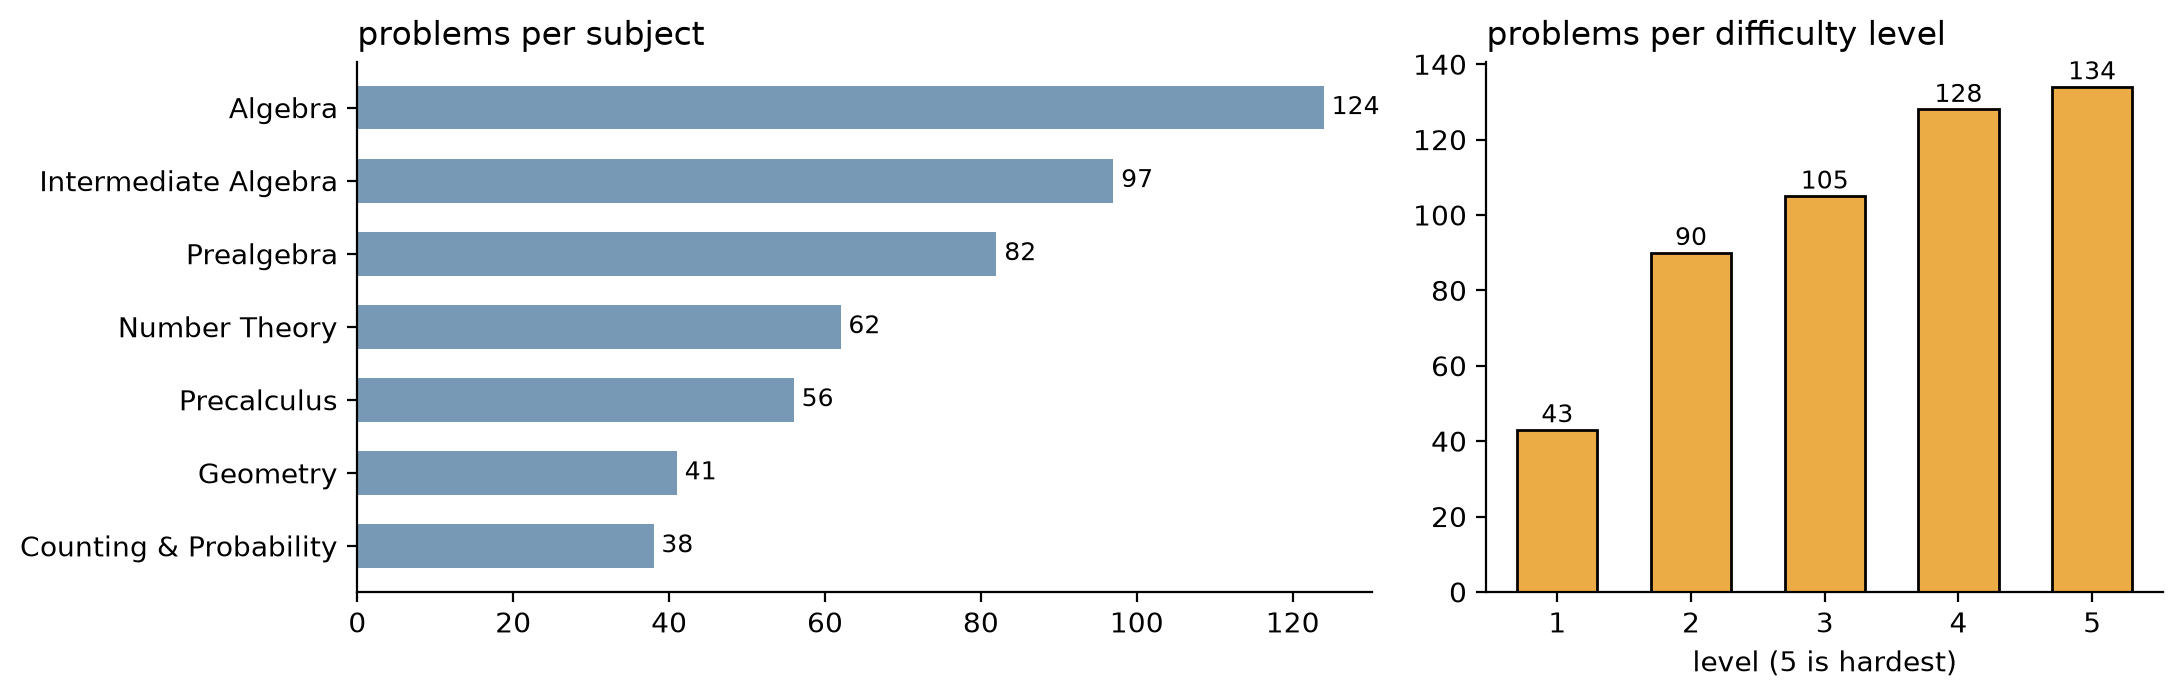

In [10]:
plot_benchmark_composition(math500)

## `Step 5`: The evaluation loop

Two choices remain. First, a **prompt template** that tells the model to box its answer, so extraction is consistent across models. Second, the loop that applies the verifier to every problem, keeps a record of each one for inspection, and reports accuracy at the end.

```mermaid
flowchart LR
    P[problem] --> T[fill the prompt template]
    T --> G[generate]
    G --> E[extract_final_answer]
    E --> V[grade against the reference]
    V --> R[record: completion, prediction, correct]
    R --> A[accuracy = correct / total]
    style G fill:#395761,color:#fff,stroke:#000
    style V fill:#CEEB13,stroke:#000
    style A fill:#ECAC45,stroke:#000
```

`evaluate_math` in `reasoning_utils/evaluate.py` is exactly that loop, plus a progress line and an optional JSON-lines log. The template it uses by default:

In [11]:
print(MATH_PROMPT.replace("{problem}", sample["problem"]))

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
The set of points $(x,y,z)$ that satisfy
\[2x = 3y = -z\]is a line.

The set of points $(x,y,z)$ that satisfy
\[6x = -y = -4z\]is another line.

Find the angle between these lines, in degrees.

Answer:


In [12]:
N = 50
subset = math500[:N]
base_eval = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024)

50/50  correct so far: 10  elapsed: 1.7 min  eta: 0.0 min                                 
accuracy: 20.0% (10/50)   avg response: 120 tokens   time: 1.7 min


A single accuracy number hides a lot. Always read a few of the failures. Most fall into three bins: the model was wrong, the model was right but wrote the answer in a form the grader did not recognize, or the model never reached an answer within the token budget. Only the first bin is about reasoning. The other two are about the harness, and they are yours to fix.

In [13]:
wrong = [r for r in base_eval["records"] if not r["correct"]]
for r in wrong[:3]:
    print("=" * 90)
    print("PROBLEM:   ", r["problem"][:200].replace("\n", " "))
    print("REFERENCE: ", r["answer"])
    print("PREDICTED: ", r["predicted"][:80])
    print("TAIL OF COMPLETION:", repr(r["completion"][-160:]))

PROBLEM:    Define \[p = \sum_{k = 1}^\infty \frac{1}{k^2} \quad \text{and} \quad q = \sum_{k = 1}^\infty \frac{1}{k^3}.\]Find a way to write \[\sum_{j = 1}^\infty \sum_{k = 1}^\infty \frac{1}{(j + k)^3}\]in term
REFERENCE:  p - q
PREDICTED:  p^2 - 2pq + q^2
TAIL OF COMPLETION: ' \\[\\boxed{p^2 - 2pq + q^2}\\]'
PROBLEM:    If $f(x) = \frac{3x-2}{x-2}$, what is the value of $f(-2) +f(-1)+f(0)$? Express your answer as a common fraction.
REFERENCE:  \frac{14}{3}
PREDICTED:  \frac{1}{2}
TAIL OF COMPLETION: ' \\boxed{\\frac{1}{2}}'
PROBLEM:    How many positive whole-number divisors does 196 have?
REFERENCE:  9
PREDICTED:  16
TAIL OF COMPLETION: ' 196 has 16 positive whole-number divisors.'


> **Swap one flag.** The post-trained checkpoint ([Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B)) loads the same way: `load_qwen3("reasoning", device=device, compile=True)`. Its tokenizer applies the chat template automatically, and because it writes long `<think>` blocks it needs a bigger budget (`max_new_tokens=2048`) and a few minutes for fifty problems. Everything else in this notebook, the verifier, the loop, the records, is unchanged. That is the point of building the harness once: comparing models is a one-line change, and the exercises at the end ask you to make it.

Fifty problems is enough to catch bugs in the harness and to see large effects. It is not enough to rank methods by a few points; for that, `scripts/evaluate_math500.py` runs the full set from the command line.

## `Step 6`: How much does the prompt matter?

A base model has never been told what a "question" is. It completes documents, so the exact wording of the template changes which documents it thinks it is in, and that changes accuracy. Let's measure it: three templates, same fifty problems, same grader.

In [14]:
templates = {
    "question / answer": MATH_PROMPT,
    "problem / solution": (
        "Solve the following problem. Show your work, then write the final result on its own line as "
        "\\boxed{ANSWER}.\n\nProblem:\n{problem}\n\nSolution:"
    ),
    "bare problem": "{problem}",
}

template_results = {"question / answer": base_eval}
for name, tpl in templates.items():
    if name not in template_results:
        print(f"[{name}]")
        template_results[name] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024, template=tpl)

[problem / solution]
50/50  correct so far: 24  elapsed: 6.7 min  eta: 0.0 min                                 
accuracy: 48.0% (24/50)   avg response: 484 tokens   time: 6.7 min
[bare problem]
50/50  correct so far: 22  elapsed: 7.6 min  eta: 0.0 min                                 
accuracy: 44.0% (22/50)   avg response: 539 tokens   time: 7.6 min


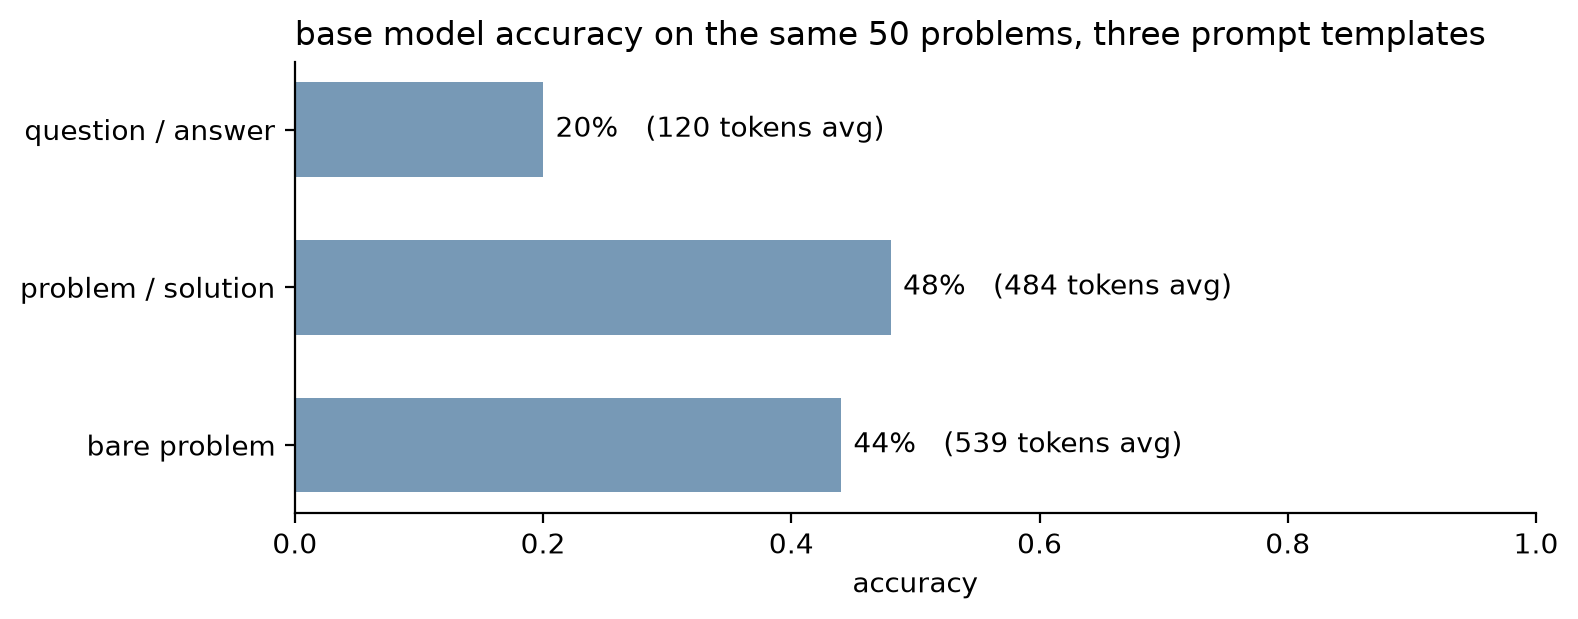

In [15]:
plot_template_comparison(template_results, title=f"base model accuracy on the same {N} problems, three prompt templates")

The spread between templates can be as large as the gap between models. Two lessons follow. First, when you compare two models, hold the template fixed and say which one you used. Second, a base model's score on a public benchmark is partly a measure of how closely your prompt resembles the training data it memorized, which is a reason to prefer held-out problems you wrote yourself when the stakes are high. Post-trained models are far less sensitive, because instruction tuning taught them what a request looks like regardless of phrasing.

## Summary

- Four evaluation methods exist; this track uses verifiers because a deterministic check on a free-form answer is both a benchmark score and, later, a reinforcement learning reward.
- A math verifier has four stages: extract the last `\boxed{}` (with fallbacks), normalize the spelling, compare symbolically with SymPy, and grade part by part. All four live in `reasoning_utils/verify.py` and are covered by tests.
- `evaluate_math` runs the verifier over a benchmark and keeps a record per problem. Read the failures, not just the number.
- Once the harness exists, comparing models is a one-line change. Small slices catch bugs; only the full set gives numbers you can rank by.
- Base models are sensitive to prompt wording. Fix the template, report it, and prefer held-out problems.

## Exercises

1. Swap in the post-trained checkpoint with `load_qwen3("reasoning", device=device, compile=True)` and run the same fifty problems with `max_new_tokens=2048`. Compare accuracy and average response length with the base model. How often does it run out of budget before closing `</think>` (look for completions with no `\boxed`)?
2. Group the fifty base-model records by `subject` instead of `level`. Which subject is hardest? Does the answer change for the post-trained checkpoint?
3. Run `scripts/evaluate_math500.py --model base --n 500 --compile`, then again with `--template-file` pointing at a file containing the "problem / solution" template. How much does the full-set number move?

## Further reading

- [Measuring Mathematical Problem Solving With the MATH Dataset](https://arxiv.org/abs/2103.03874) (Hendrycks et al., 2021), the source of these problems
- [Let's Verify Step by Step](https://arxiv.org/abs/2305.20050) (Lightman et al., 2023), which introduced the 500-problem test split
- [SymPy documentation](https://docs.sympy.org/latest/index.html), in particular [`simplify`](https://docs.sympy.org/latest/modules/simplify/simplify.html) and [`parse_expr`](https://docs.sympy.org/latest/modules/parsing.html)
- [Python `re` module](https://docs.python.org/3/library/re.html), for the normalization rules in `verify.py`
- [A Careful Examination of Large Language Model Performance on Grade School Arithmetic](https://arxiv.org/abs/2405.00332) (Zhang et al., 2024), on benchmark contamination and why held-out problems matter

Next up in this track: inference-time scaling, where we make the base model reason better without touching a single weight, and measure it with the harness you just used.